# CS6109 / Reinforcement Learning – Assignment 3
**ADP and Q-Learning** – all algorithms implemented from scratch with Python/NumPy (matplotlib used only for plots).

In [ ]:
"""
CS6109 / Reinforcement Learning - Assignment 3
Khushi Kumari(2611AI49)
"""
import numpy as np
import matplotlib.pyplot as plt

SEED = 42
LINE = "=" * 72


def header(t):
    print("\n" + LINE + "\n" + t + "\n" + LINE)

## Frozen Lake environment and shared helpers (deterministic 4×4)
States 0..15 row-wise; actions 0=Left,1=Down,2=Right,3=Up; invalid move keeps state; holes/goal terminal; R=+1 at goal.

In [2]:
MAP = ["SFFF",
       "FHFH",
       "FFFH",
       "HFFG"]
NS, NA = 16, 4
ACTIONS = {0: (0, -1), 1: (1, 0), 2: (0, 1), 3: (-1, 0)}  # Left, Down, Right, Up
ARROW = {0: "<", 1: "v", 2: ">", 3: "^"}
HOLES = {i for i in range(16) if MAP[i // 4][i % 4] == "H"}
GOAL = 15
TERMINAL = HOLES | {GOAL}


def env_step(s, a):
    r, c = divmod(s, 4)
    dr, dc = ACTIONS[a]
    nr, nc = r + dr, c + dc
    if not (0 <= nr < 4 and 0 <= nc < 4):  # invalid move -> stay
        nr, nc = r, c
    s2 = nr * 4 + nc
    reward = 1.0 if s2 == GOAL else 0.0
    return s2, reward, s2 in TERMINAL


def q_update(Q, s, a, r, s2, done, alpha, gamma):
    target = r if done else r + gamma * np.max(Q[s2])
    err = target - Q[s, a]
    Q[s, a] += alpha * err
    return target, err


def train(episodes, alpha, gamma, eps_fn, seed, max_steps=100, tie="random"):
    """eps_fn(episode_idx) -> epsilon used in that episode.
    Returns Q, per-episode success flags, #exploratory actions, epsilons used."""
    rng = np.random.default_rng(seed)
    Q = np.zeros((NS, NA))
    succ = np.zeros(episodes, dtype=int)
    explore = 0
    eps_hist = np.zeros(episodes)
    for ep in range(episodes):
        eps = eps_fn(ep)
        eps_hist[ep] = eps
        s = 0
        for _ in range(max_steps):
            if rng.random() < eps:            # exploratory action
                a = int(rng.integers(NA))
                explore += 1
            else:                             # greedy, ties broken uniformly at random
                q = Q[s]
                if tie == "first":            # plain argmax: ties -> lowest index (Left)
                    a = int(np.argmax(q))
                else:
                    a = int(rng.choice(np.flatnonzero(q == q.max())))
            s2, r, done = env_step(s, a)
            q_update(Q, s, a, r, s2, done, alpha, gamma)
            s = s2
            if done:
                succ[ep] = int(s == GOAL)
                break
    return Q, succ, explore, eps_hist


def greedy_policy(Q):
    return [None if s in TERMINAL else int(np.argmax(Q[s])) for s in range(NS)]


def policy_grid(Q):
    rows = []
    for r in range(4):
        row = []
        for c in range(4):
            s = r * 4 + c
            if s == GOAL:
                row.append("G")
            elif s in HOLES:
                row.append("H")
            elif not np.any(Q[s]):
                row.append(".")   # never learned (all Q = 0)
            else:
                row.append(ARROW[int(np.argmax(Q[s]))])
        rows.append("  " + " ".join(row))
    return "\n".join(rows)


def greedy_rollout(Q, max_steps=100):
    s, path = 0, [0]
    for _ in range(max_steps):
        s, _, done = env_step(s, int(np.argmax(Q[s])))
        path.append(s)
        if done:
            return s == GOAL, path
    return False, path


def windowed(succ, w):
    return succ.reshape(-1, w).mean(axis=1) * 100

## Q1. Passive ADP: model and utility update

In [3]:
def q1():
    header("Q1. Passive ADP: model and utility update")
    gamma = 0.9
    A = ["Up", "Down", "Left", "Right"]
    states = ["s11", "s12", "s21", "s22"]
    R = {"s11": -0.04, "s21": -0.04, "s12": 1.0, "s22": -1.0}
    terminal = {"s12", "s22"}
    policy = {"s11": "Down", "s21": "Right"}

    # Grid:   s11 s12(+1)
    #         s21 s22(-1)
    # N(s,a) = 5 initially for every (s,a).
    N_sa = {(s, a): 5 for s in ["s11", "s21"] for a in A}

    # Outcome counts for the policy actions (intended = 3, left/right of the
    # intended direction = 1 each, total 5 = N(s,a)).
    #   s11, Down : intended -> s21 (3) ; Right-of-Down(=Left) -> wall -> s11 (1);
    #               Left-of-Down(=Right) -> s12 (1)
    #   s21, Right: intended -> s22 (3) ; Up -> s11 (1) ; Down -> wall -> s21 (1)
    N_sas = {
        ("s11", "Down", "s21"): 3, ("s11", "Down", "s11"): 1, ("s11", "Down", "s12"): 1,
        ("s21", "Right", "s22"): 3, ("s21", "Right", "s11"): 1, ("s21", "Right", "s21"): 1,
    }
    print("Initial counts: N(s11,Down) =", N_sa[("s11", "Down")],
          "| N(s11,Down,s21) =", N_sas[("s11", "Down", "s21")])
    print("Initial P(s21|s11,Down) =", N_sas[("s11", "Down", "s21")] / N_sa[("s11", "Down")])

    # ---- observe <s11, Down, s21, -0.04> ----
    N_sa[("s11", "Down")] += 1
    N_sas[("s11", "Down", "s21")] += 1

    def P(s2, s, a):
        return N_sas.get((s, a, s2), 0) / N_sa[(s, a)]

    print("\nAfter observing <s11, Down, s21, -0.04>:")
    print("  N(s11,Down)        =", N_sa[("s11", "Down")])
    print("  N(s11,Down,s21)    =", N_sas[("s11", "Down", "s21")])
    print("  P(s21|s11,Down)    = %d/%d = %.4f" %
          (N_sas[("s11", "Down", "s21")], N_sa[("s11", "Down")], P("s21", "s11", "Down")))
    print("  P(s12|s11,Down)    = %.4f , P(s11|s11,Down) = %.4f" %
          (P("s12", "s11", "Down"), P("s11", "s11", "Down")))
    print("  (s21,Right) model  : P(s22)=%.2f P(s11)=%.2f P(s21)=%.2f" %
          (P("s22", "s21", "Right"), P("s11", "s21", "Right"), P("s21", "s21", "Right")))

    # ---- Bellman equations  V(s) = R(s) + gamma * sum_s' P(s'|s,pi(s)) V(s')
    # Terminal utilities: V(s12)=+1, V(s22)=-1.
    V_term = {"s12": 1.0, "s22": -1.0}
    free = ["s11", "s21"]
    idx = {s: i for i, s in enumerate(free)}
    M = np.eye(2)
    b = np.zeros(2)
    print("\nBellman equations (policy evaluation):")
    for s in free:
        a = policy[s]
        b[idx[s]] = R[s]
        terms = []
        for s2 in states:
            p = P(s2, s, a)
            if p == 0:
                continue
            if s2 in terminal:
                b[idx[s]] += gamma * p * V_term[s2]
            else:
                M[idx[s], idx[s2]] -= gamma * p
            terms.append("%.4f*V(%s)" % (p, s2))
        print("  V(%s) = %.2f + %.1f*[%s]" % (s, R[s], gamma, " + ".join(terms)))
    V = np.linalg.solve(M, b)
    print("\nLinear system  (I - gamma*P) V = b :")
    print("  M =\n", np.round(M, 4), "\n  b =", np.round(b, 4))
    print("\nSolved utilities:")
    print("  V(s11) = %.4f" % V[idx["s11"]])
    print("  V(s21) = %.4f" % V[idx["s21"]])
    print("  V(s12) = +1 , V(s22) = -1 (terminal)")

    # cross-check with iterative policy evaluation
    Vi = {"s11": 0.0, "s21": 0.0, "s12": 1.0, "s22": -1.0}
    for _ in range(2000):
        new = dict(Vi)
        for s in free:
            new[s] = R[s] + gamma * sum(P(s2, s, policy[s]) * Vi[s2] for s2 in states)
        Vi = new
    print("  (iterative check: V(s11)=%.4f, V(s21)=%.4f)" % (Vi["s11"], Vi["s21"]))

q1()


Q1. Passive ADP: model and utility update
Initial counts: N(s11,Down) = 5 | N(s11,Down,s21) = 3
Initial P(s21|s11,Down) = 0.6

After observing <s11, Down, s21, -0.04>:
  N(s11,Down)        = 6
  N(s11,Down,s21)    = 4
  P(s21|s11,Down)    = 4/6 = 0.6667
  P(s12|s11,Down)    = 0.1667 , P(s11|s11,Down) = 0.1667
  (s21,Right) model  : P(s22)=0.60 P(s11)=0.20 P(s21)=0.20

Bellman equations (policy evaluation):
  V(s11) = -0.04 + 0.9*[0.1667*V(s11) + 0.1667*V(s12) + 0.6667*V(s21)]
  V(s21) = -0.04 + 0.9*[0.2000*V(s11) + 0.2000*V(s21) + 0.6000*V(s22)]

Linear system  (I - gamma*P) V = b :
  M =
 [[ 0.85 -0.6 ]
 [-0.18  0.82]] 
  b = [ 0.11 -0.58]

Solved utilities:
  V(s11) = -0.4377
  V(s21) = -0.8034
  V(s12) = +1 , V(s22) = -1 (terminal)
  (iterative check: V(s11)=-0.4377, V(s21)=-0.8034)


## Q2. Temporal-Difference and Q-Learning update

In [4]:
def q2():
    header("Q2. Temporal-Difference / Q-Learning update")
    alpha, gamma = 0.5, 0.9
    Q = np.zeros((NS, NA))
    # sample transitions (s, a, r, s', done) in the 4x4 Frozen Lake
    samples = [
        (14, 2, 1.0, 15, True),    # reaches goal (terminal) -> target = r
        (13, 2, 0.0, 14, False),   # bootstraps from Q(14,.)
        (10, 1, 0.0, 14, False),   # bootstraps from Q(14,.)
        (1, 1, 0.0, 5, True),      # falls into hole (terminal) -> target = r = 0
        (14, 2, 1.0, 15, True),    # repeat: Q moves closer to 1
        (13, 2, 0.0, 14, False),   # repeat: now uses larger Q(14,Right)
    ]
    print("alpha=%.1f gamma=%.1f ; Q initialised to zeros (16x4)\n" % (alpha, gamma))
    names = {0: "Left", 1: "Down", 2: "Right", 3: "Up"}
    for i, (s, a, r, s2, done) in enumerate(samples, 1):
        old = Q[s, a]
        target, err = q_update(Q, s, a, r, s2, done, alpha, gamma)
        print("Transition %d: (s=%d, a=%s, r=%.1f, s'=%d%s)" %
              (i, s, names[a], r, s2, ", terminal" if done else ""))
        if done:
            print("   TD_Target = r = %.4f" % target)
        else:
            print("   TD_Target = r + gamma*max_a' Q(s',a') = %.1f + %.1f*%.4f = %.4f"
                  % (r, gamma, np.max(Q[s2]), target))
        print("   Current Q(s,a) = %.4f | TD_Error = %.4f - %.4f = %.4f | Updated Q(s,a) = %.4f\n"
              % (old, target, old, err, Q[s, a]))

q2()


Q2. Temporal-Difference / Q-Learning update
alpha=0.5 gamma=0.9 ; Q initialised to zeros (16x4)

Transition 1: (s=14, a=Right, r=1.0, s'=15, terminal)
   TD_Target = r = 1.0000
   Current Q(s,a) = 0.0000 | TD_Error = 1.0000 - 0.0000 = 1.0000 | Updated Q(s,a) = 0.5000

Transition 2: (s=13, a=Right, r=0.0, s'=14)
   TD_Target = r + gamma*max_a' Q(s',a') = 0.0 + 0.9*0.5000 = 0.4500
   Current Q(s,a) = 0.0000 | TD_Error = 0.4500 - 0.0000 = 0.4500 | Updated Q(s,a) = 0.2250

Transition 3: (s=10, a=Down, r=0.0, s'=14)
   TD_Target = r + gamma*max_a' Q(s',a') = 0.0 + 0.9*0.5000 = 0.4500
   Current Q(s,a) = 0.0000 | TD_Error = 0.4500 - 0.0000 = 0.4500 | Updated Q(s,a) = 0.2250

Transition 4: (s=1, a=Down, r=0.0, s'=5, terminal)
   TD_Target = r = 0.0000
   Current Q(s,a) = 0.0000 | TD_Error = 0.0000 - 0.0000 = 0.0000 | Updated Q(s,a) = 0.0000

Transition 5: (s=14, a=Right, r=1.0, s'=15, terminal)
   TD_Target = r = 1.0000
   Current Q(s,a) = 0.5000 | TD_Error = 1.0000 - 0.5000 = 0.5000 | Updat

## Q3. Exploration vs. exploitation


Q3. Exploration vs. exploitation (Frozen Lake, 2000 episodes)

--- epsilon = 0.0 ---
Total successful episodes : 1900 / 2000
Final success rate (last 100 eps): 100.0%
Total exploratory actions : 0
Greedy policy (<,v,>,^ ; '.'=never learned; H hole; G goal):
  > > v .
  . H v H
  . . v H
  H . > G
Greedy rollout from S reaches goal: True  path=[0, 1, 2, 6, 10, 14, 15]

--- epsilon = 0.1 ---
Total successful episodes : 1712 / 2000
Final success rate (last 100 eps): 91.0%
Total exploratory actions : 1242
Greedy policy (<,v,>,^ ; '.'=never learned; H hole; G goal):
  > > v <
  ^ H v H
  > > v H
  H ^ > G
Greedy rollout from S reaches goal: True  path=[0, 1, 2, 6, 10, 14, 15]

--- epsilon = 0.3 ---
Total successful episodes : 1250 / 2000
Final success rate (last 100 eps): 64.0%
Total exploratory actions : 4197
Greedy policy (<,v,>,^ ; '.'=never learned; H hole; G goal):
  v > v <
  v H v H
  > > v H
  H > > G
Greedy rollout from S reaches goal: True  path=[0, 4, 8, 9, 10, 14, 15]

--- epsi

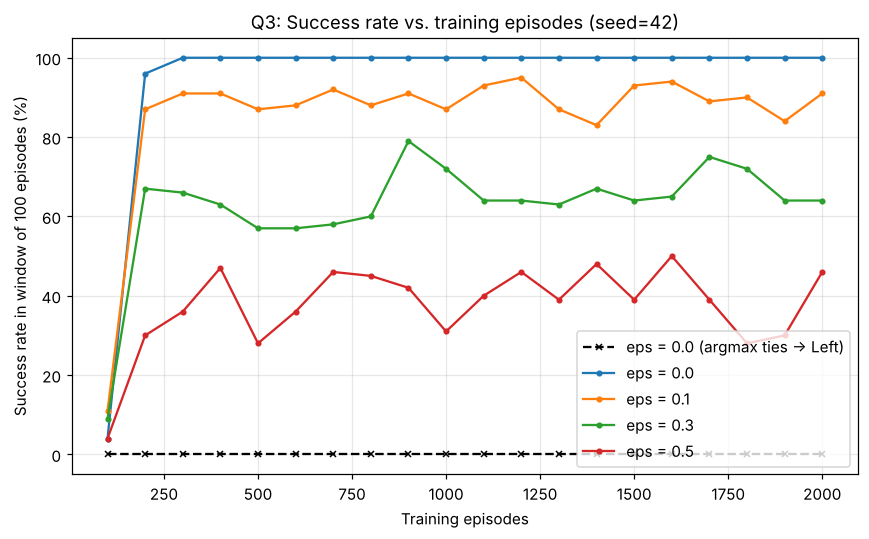


Robustness check, mean over 20 seeds (final-window success %, total successes):
  eps=0.0 : final window 100.0% , total successes 1871
  eps=0.1 : final window 88.7% , total successes 1670
  eps=0.3 : final window 66.0% , total successes 1232
  eps=0.5 : final window 39.5% , total successes 765


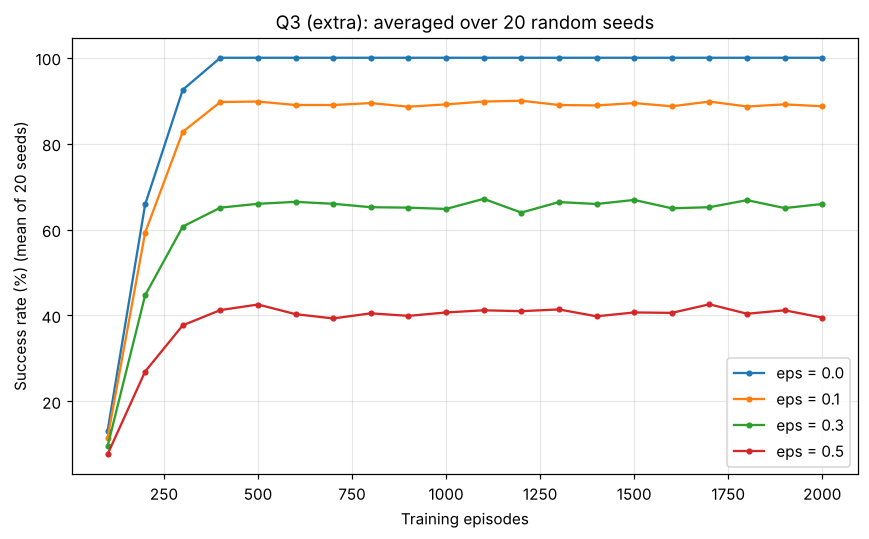


Why can a purely greedy agent fail?
  Q starts at all zeros and the only non-zero reward is +1 at the goal, so for a
  long time every action looks equally good (a tie). A purely greedy agent
  (eps = 0) only exploits what it already knows, and it knows nothing: with
  plain argmax it always breaks ties with action 0 (Left). From S=0 'Left' is an
  invalid move, so it stays in state 0 for all 100 steps, never sees a reward,
  and every TD-target is 0 + gamma*0 = 0, so Q never changes: 0 successes in
  2000 episodes (see the extra eps=0 / argmax run above). The agent can never
  discover the good policy because it never tries anything else.
  In the random-tie-break run, eps=0 happens to succeed, but only because the
  random tie-breaking is itself a hidden form of exploration. Even then the
  agent commits to the first path it finds (many states stay unlearned, '.'),
  which is luck and not guaranteed optimal or robust; in a larger/stochastic
  map it would lock into a poor policy.
  

In [5]:
def q3(EPISODES=2000, W=100):
    header("Q3. Exploration vs. exploitation (Frozen Lake, %d episodes)" % EPISODES)
    alpha, gamma = 0.5, 0.9
    eps_list = [0.0, 0.1, 0.3, 0.5]
    results = {}
    for eps in eps_list:
        Q, succ, expl, _ = train(EPISODES, alpha, gamma, lambda e, eps=eps: eps, SEED)
        results[eps] = (Q, succ, expl)
        ok, path = greedy_rollout(Q)
        print("\n--- epsilon = %.1f ---" % eps)
        print("Total successful episodes : %d / %d" % (succ.sum(), EPISODES))
        print("Final success rate (last %d eps): %.1f%%" % (W, succ[-W:].mean() * 100))
        print("Total exploratory actions : %d" % expl)
        print("Greedy policy (<,v,>,^ ; '.'=never learned; H hole; G goal):")
        print(policy_grid(Q))
        print("Greedy rollout from S reaches goal: %s  path=%s" % (ok, path if ok else path[:6] + ["..."]))

    # extra: purely greedy agent with plain argmax tie-breaking (always picks Left on ties)
    Qg, sg, eg, _ = train(EPISODES, alpha, gamma, lambda e: 0.0, SEED, tie="first")
    print("\n--- epsilon = 0.0 with plain argmax tie-breaking (ties -> Left) ---")
    print("Total successful episodes : %d / %d | final success rate %.1f%% | exploratory actions %d"
          % (sg.sum(), EPISODES, sg[-W:].mean() * 100, eg))
    print("Greedy policy:"); print(policy_grid(Qg))
    print("Q-table all zeros:", not np.any(Qg))
    results_g = sg

    # plot
    plt.figure(figsize=(8, 5))
    x = np.arange(1, EPISODES // W + 1) * W
    plt.plot(x, windowed(results_g, W), "k--", marker="x", ms=4, label="eps = 0.0 (argmax ties -> Left)")
    for eps in eps_list:
        plt.plot(x, windowed(results[eps][1], W), marker="o", ms=3, label="eps = %.1f" % eps)
    plt.xlabel("Training episodes"); plt.ylabel("Success rate in window of %d episodes (%%)" % W)
    plt.title("Q3: Success rate vs. training episodes (seed=%d)" % SEED)
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig("q3_success_rate.png", dpi=150); plt.show()

    # robustness: mean over 20 seeds
    plt.figure(figsize=(8, 5))
    print("\nRobustness check, mean over 20 seeds (final-window success %, total successes):")
    for eps in eps_list:
        curves, finals, tots = [], [], []
        for sd in range(20):
            _, sc, _, _ = train(EPISODES, alpha, gamma, lambda e, eps=eps: eps, 1000 + sd)
            curves.append(windowed(sc, W)); finals.append(sc[-W:].mean() * 100); tots.append(sc.sum())
        plt.plot(x, np.mean(curves, axis=0), marker="o", ms=3, label="eps = %.1f" % eps)
        print("  eps=%.1f : final window %.1f%% , total successes %.0f" % (eps, np.mean(finals), np.mean(tots)))
    plt.xlabel("Training episodes"); plt.ylabel("Success rate (%) (mean of 20 seeds)")
    plt.title("Q3 (extra): averaged over 20 random seeds")
    plt.grid(alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig("q3_success_rate_20seeds.png", dpi=150); plt.show()

    print("""
Why can a purely greedy agent fail?
  Q starts at all zeros and the only non-zero reward is +1 at the goal, so for a
  long time every action looks equally good (a tie). A purely greedy agent
  (eps = 0) only exploits what it already knows, and it knows nothing: with
  plain argmax it always breaks ties with action 0 (Left). From S=0 'Left' is an
  invalid move, so it stays in state 0 for all 100 steps, never sees a reward,
  and every TD-target is 0 + gamma*0 = 0, so Q never changes: 0 successes in
  2000 episodes (see the extra eps=0 / argmax run above). The agent can never
  discover the good policy because it never tries anything else.
  In the random-tie-break run, eps=0 happens to succeed, but only because the
  random tie-breaking is itself a hidden form of exploration. Even then the
  agent commits to the first path it finds (many states stay unlearned, '.'),
  which is luck and not guaranteed optimal or robust; in a larger/stochastic
  map it would lock into a poor policy.
  Trade-off seen in the results: larger eps keeps exploring (more exploratory
  actions) but its on-policy success rate during training drops (eps=0.5 ~ 40-46%)
  because random moves often fall into holes; small eps (0.1) gives a good
  balance. The learned greedy policy reaches the goal for every eps tested
  (except plain-argmax eps=0).""")

q3()

## Q4. Tabular Q-learning on Frozen Lake

In [6]:
def q4():
    header("Q4. Tabular Q-learning on 4x4 Frozen Lake")
    alpha, gamma, eps = 0.5, 0.9, 0.2
    Q, succ, expl, _ = train(2000, alpha, gamma, lambda e: eps, SEED)
    np.set_printoptions(precision=4, suppress=True, linewidth=120)
    print("alpha=%.1f gamma=%.1f eps=%.1f episodes=2000 max_steps=100" % (alpha, gamma, eps))
    print("\nFinal Q-table (rows = states 0..15; cols = Left, Down, Right, Up):")
    print("state |    Left      Down     Right       Up")
    for s in range(NS):
        print("%5d | %9.4f %9.4f %9.4f %9.4f" % (s, *Q[s]))
    pol = greedy_policy(Q)
    print("\nLearned greedy policy pi(s)=argmax_a Q(s,a)  (0=L,1=D,2=R,3=U; None = terminal):")
    print(pol)
    print("\nPolicy grid:")
    print(policy_grid(Q))
    ok, path = greedy_rollout(Q)
    print("\nGreedy rollout from S: reaches goal = %s, path = %s (length %d steps)"
          % (ok, path, len(path) - 1))
    print("Optimal value at start V*(0) = gamma^5 = %.4f ; learned max Q(0,.) = %.4f"
          % (gamma ** 5, Q[0].max()))
    print("Training success rate (last 100 eps): %.1f%%" % (succ[-100:].mean() * 100))
    return Q

q4()


Q4. Tabular Q-learning on 4x4 Frozen Lake
alpha=0.5 gamma=0.9 eps=0.2 episodes=2000 max_steps=100

Final Q-table (rows = states 0..15; cols = Left, Down, Right, Up):
state |    Left      Down     Right       Up
    0 |    0.5314    0.5905    0.5905    0.5314
    1 |    0.5314    0.0000    0.6561    0.5905
    2 |    0.5905    0.7290    0.5905    0.6561
    3 |    0.6561    0.0000    0.5720    0.5167
    4 |    0.5905    0.6561    0.0000    0.5314
    5 |    0.0000    0.0000    0.0000    0.0000
    6 |    0.0000    0.8100    0.0000    0.6561
    7 |    0.0000    0.0000    0.0000    0.0000
    8 |    0.6561    0.0000    0.7290    0.5905
    9 |    0.6561    0.8100    0.8100    0.0000
   10 |    0.7290    0.9000    0.0000    0.7290
   11 |    0.0000    0.0000    0.0000    0.0000
   12 |    0.0000    0.0000    0.0000    0.0000
   13 |    0.0000    0.8049    0.9000    0.7290
   14 |    0.8100    0.9000    1.0000    0.8100
   15 |    0.0000    0.0000    0.0000    0.0000

Learned greedy poli

## Q5. Decaying exploration challenge


Q5. Decaying exploration vs. fixed epsilon

--- fixed eps=0.2 ---
Total successful episodes : 1480 / 2000
Final success rate (last 100 training eps): 77.0%
Total exploratory actions : 2643
Greedy-policy success (no exploration): True, path=[0, 4, 8, 9, 10, 14, 15]
Final Q-table:
state |    Left      Down     Right       Up
    0 |    0.5314    0.5905    0.5905    0.5314
    1 |    0.5314    0.0000    0.6561    0.5905
    2 |    0.5905    0.7290    0.5905    0.6561
    3 |    0.6561    0.0000    0.5720    0.5167
    4 |    0.5905    0.6561    0.0000    0.5314
    5 |    0.0000    0.0000    0.0000    0.0000
    6 |    0.0000    0.8100    0.0000    0.6561
    7 |    0.0000    0.0000    0.0000    0.0000
    8 |    0.6561    0.0000    0.7290    0.5905
    9 |    0.6561    0.8100    0.8100    0.0000
   10 |    0.7290    0.9000    0.0000    0.7290
   11 |    0.0000    0.0000    0.0000    0.0000
   12 |    0.0000    0.0000    0.0000    0.0000
   13 |    0.0000    0.8049    0.9000    0.7290
  

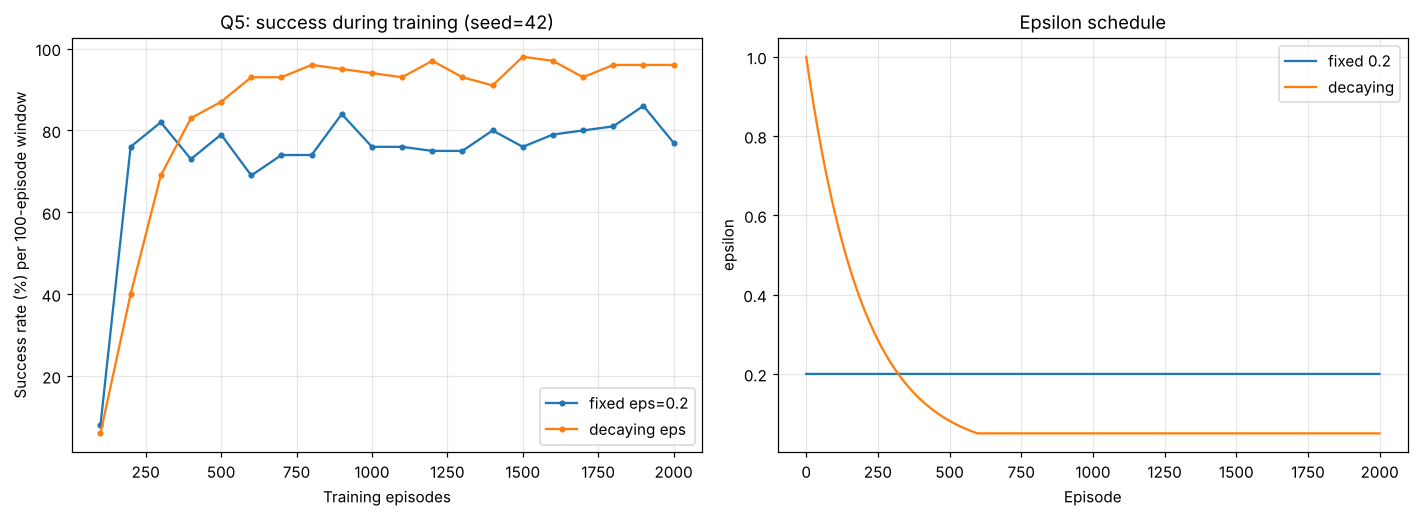


Robustness, mean over 20 seeds:
  fixed eps=0.2  final-window success 78.1% | exploratory actions 2640 | greedy policy reaches goal 20/20
  decaying eps   final-window success 94.8% | exploratory actions 1772 | greedy policy reaches goal 20/20

Effect of decreasing exploration:
  Early on, eps near 1 makes the agent act almost randomly, so it visits many
  states and finds the goal reward quickly; the +1 then spreads backwards through
  Q. As eps decays towards 0.05 the agent increasingly exploits what it has
  learned, so almost every late episode follows the near-optimal path and the
  training success rate rises close to 100%, clearly above fixed eps=0.2
  (which keeps taking ~20% random moves, so it keeps falling into holes
  even with a good Q-table). Decay also uses fewer exploratory actions in
  total. Both end with a greedy policy that reaches the goal in the optimal 6
  steps (there are several equally optimal paths, so the arrows can differ),
  but decaying eps gives better 

In [7]:
def q5(EPISODES=2000, W=100):
    header("Q5. Decaying exploration vs. fixed epsilon")
    alpha, gamma = 0.5, 0.9
    eps0, eps_min, decay = 1.0, 0.05, 0.995

    def decaying(ep):                       # eps_{t+1} = max(eps_min, eps_t*decay)
        return max(eps_min, eps0 * decay ** ep)

    cfg = {"fixed eps=0.2": lambda e: 0.2, "decaying eps": decaying}
    res = {}
    for name, fn in cfg.items():
        Q, succ, expl, eh = train(EPISODES, alpha, gamma, fn, SEED)
        res[name] = (Q, succ, expl, eh)
        ok, path = greedy_rollout(Q)
        print("\n--- %s ---" % name)
        print("Total successful episodes : %d / %d" % (succ.sum(), EPISODES))
        print("Final success rate (last %d training eps): %.1f%%" % (W, succ[-W:].mean() * 100))
        print("Total exploratory actions : %d" % expl)
        print("Greedy-policy success (no exploration): %s, path=%s" % (ok, path if ok else "fails"))
        print("Final Q-table:")
        print("state |    Left      Down     Right       Up")
        for s in range(NS):
            print("%5d | %9.4f %9.4f %9.4f %9.4f" % (s, *Q[s]))
        print("Learned greedy policy (0=L,1=D,2=R,3=U):", greedy_policy(Q))
        print(policy_grid(Q))
    eh = res["decaying eps"][3]
    print("\nDecaying schedule: eps at episode 0=%.3f, 100=%.3f, 300=%.3f, reaches eps_min=0.05 at episode %d"
          % (eh[0], eh[100], eh[300], int(np.argmax(eh <= eps_min + 1e-12))))

    x = np.arange(1, EPISODES // W + 1) * W
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    for name, (Q, succ, expl, eh) in res.items():
        ax[0].plot(x, windowed(succ, W), marker="o", ms=3, label=name)
    ax[0].set_xlabel("Training episodes"); ax[0].set_ylabel("Success rate (%%) per %d-episode window" % W)
    ax[0].set_title("Q5: success during training (seed=%d)" % SEED); ax[0].grid(alpha=.3); ax[0].legend()
    ax[1].plot(res["fixed eps=0.2"][3], label="fixed 0.2")
    ax[1].plot(eh, label="decaying")
    ax[1].set_xlabel("Episode"); ax[1].set_ylabel("epsilon"); ax[1].set_title("Epsilon schedule")
    ax[1].grid(alpha=.3); ax[1].legend()
    plt.tight_layout(); plt.savefig("q5_decay_vs_fixed.png", dpi=150); plt.show()

    # robustness over 20 seeds
    print("\nRobustness, mean over 20 seeds:")
    for name, fn in cfg.items():
        fin, expl_l, gs = [], [], []
        for sd in range(20):
            Q, sc, ex, _ = train(EPISODES, alpha, gamma, fn, 2000 + sd)
            fin.append(sc[-W:].mean() * 100); expl_l.append(ex); gs.append(greedy_rollout(Q)[0])
        print("  %-14s final-window success %.1f%% | exploratory actions %.0f | greedy policy reaches goal %d/20"
              % (name, np.mean(fin), np.mean(expl_l), sum(gs)))

    print("""
Effect of decreasing exploration:
  Early on, eps near 1 makes the agent act almost randomly, so it visits many
  states and finds the goal reward quickly; the +1 then spreads backwards through
  Q. As eps decays towards 0.05 the agent increasingly exploits what it has
  learned, so almost every late episode follows the near-optimal path and the
  training success rate rises close to 100%, clearly above fixed eps=0.2
  (which keeps taking ~20% random moves, so it keeps falling into holes
  even with a good Q-table). Decay also uses fewer exploratory actions in
  total. Both end with a greedy policy that reaches the goal in the optimal 6
  steps (there are several equally optimal paths, so the arrows can differ),
  but decaying eps gives better on-policy performance: explore first, exploit later.""")

q5()